# Chapter 6

Python version of the R code for Chapter 6 of *In All Likelihood* (Pawitan, 2001).

R's `lm()` and `glm()` are replaced by `statsmodels`; `coef_table()` prints
the equivalent of R's `summary(fit)$coef`.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats, optimize

from statsmodels.tools.sm_exceptions import DomainWarning, PerfectSeparationWarning

from helpers import DATA, scan, li, approx, qqnorm, qqline, coef_table

# statsmodels warns that the inverse link of the Gamma GLM (R's default) is
# not guaranteed to keep the mean positive.
warnings.simplefilter("ignore", DomainWarning)

## Example 6.1 (`EX6-1.R`)

8580.714285714284 0.03342105263157895


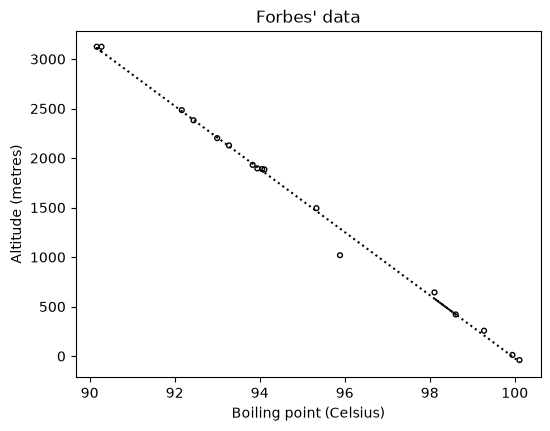

In [2]:
x = scan("forbes.dat", skip=8).reshape(-1, 2)

temp = (x[:, 0] - 32) * 5 / 9
alt = -(287 * 293 / 9.8) * np.log(x[:, 1] * 25.4 / 760)
print(287 * 293 / 9.8, 25.4 / 760)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(temp, alt, s=12, facecolors="none", edgecolors="k")

a = sm.OLS(alt, sm.add_constant(temp)).fit()
ax.plot(temp, a.fittedvalues, "k:")

ax.set_xlabel("Boiling point (Celsius)")
ax.set_ylabel("Altitude (metres)")
ax.set_title("Forbes' data")
plt.show()

## Example 6.2 (`EX6-2.R`)

               Estimate  Std. Error      value  Pr(>|value|)
(Intercept)  157.333333    4.665833  33.720313  5.226863e-09
x0             9.232264    1.417528   6.512931  3.300975e-04


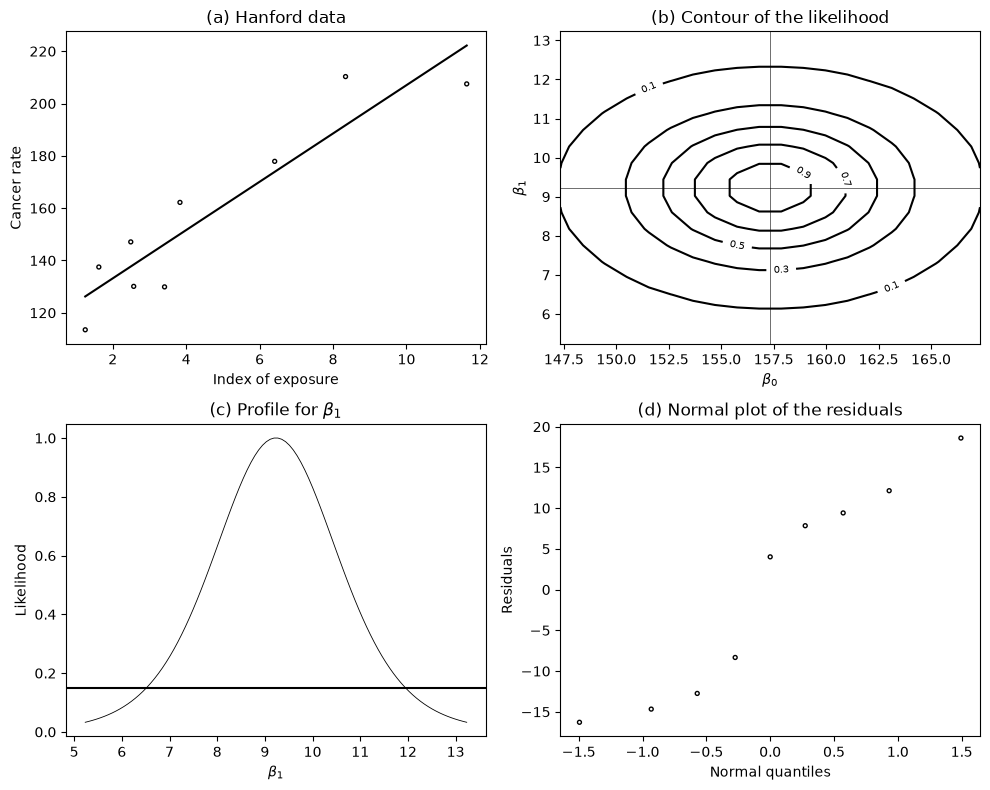

In [3]:
x, y = np.loadtxt(DATA / "hanford.dat", skiprows=6, usecols=(1, 2), unpack=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(x, y, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Index of exposure")
ax.set_ylabel("Cancer rate")
ax.set_title("(a) Hanford data")
x0 = x - x.mean()
xlm = sm.OLS(y, sm.add_constant(x0)).fit()
print(coef_table(xlm, ["(Intercept)", "x0"]))

bohat, b1hat = xlm.params
muhat = bohat + b1hat * x0
order = np.argsort(x)
ax.plot(x[order], muhat[order], "k-")

n = len(x)


def fun1(bo, b1):
    return -n / 2 * np.log(np.sum((y - bo - b1 * x0) ** 2))


bbo = np.linspace(bohat - 10, bohat + 10, 20)
bb1 = np.linspace(b1hat - 4, b1hat + 4, 20)
ll = np.array([[fun1(bo, b1) for b1 in bb1] for bo in bbo])
lik = np.exp(ll - ll.max())

ax = axes[1]
cs = ax.contour(bbo, bb1, lik.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=7)
ax.axhline(b1hat, color="k", lw=0.4)
ax.axvline(bohat, color="k", lw=0.4)
ax.set_xlabel(r"$\beta_0$")
ax.set_ylabel(r"$\beta_1$")
ax.set_title("(b) Contour of the likelihood")

bb1 = np.linspace(b1hat - 4, b1hat + 4, 100)


def fun2(b1):
    bo = y.mean()
    return -n / 2 * np.log(np.sum((y - bo - b1 * x0) ** 2))


ll = np.array([fun2(b1) for b1 in bb1])
like = np.exp(ll - ll.max())
ax = axes[2]
ax.plot(bb1, like, "k-", lw=0.6)
ax.axhline(.15, color="k")
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(c) Profile for $\beta_1$")

ax = axes[3]
q, s = qqnorm(xlm.resid)
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Normal quantiles")
ax.set_ylabel("Residuals")
ax.set_title("(d) Normal plot of the residuals")

fig.tight_layout()
plt.show()

## Example 6.3 (`EX6-3.R`)

Bernoulli data.

             Estimate  Std. Error     value  Pr(>|value|)
(Intercept) -0.722636    0.367708 -1.965246      0.049386
x0           0.159855    0.072590  2.202157      0.027654
95% CI for beta1= [0.027 0.32 ]


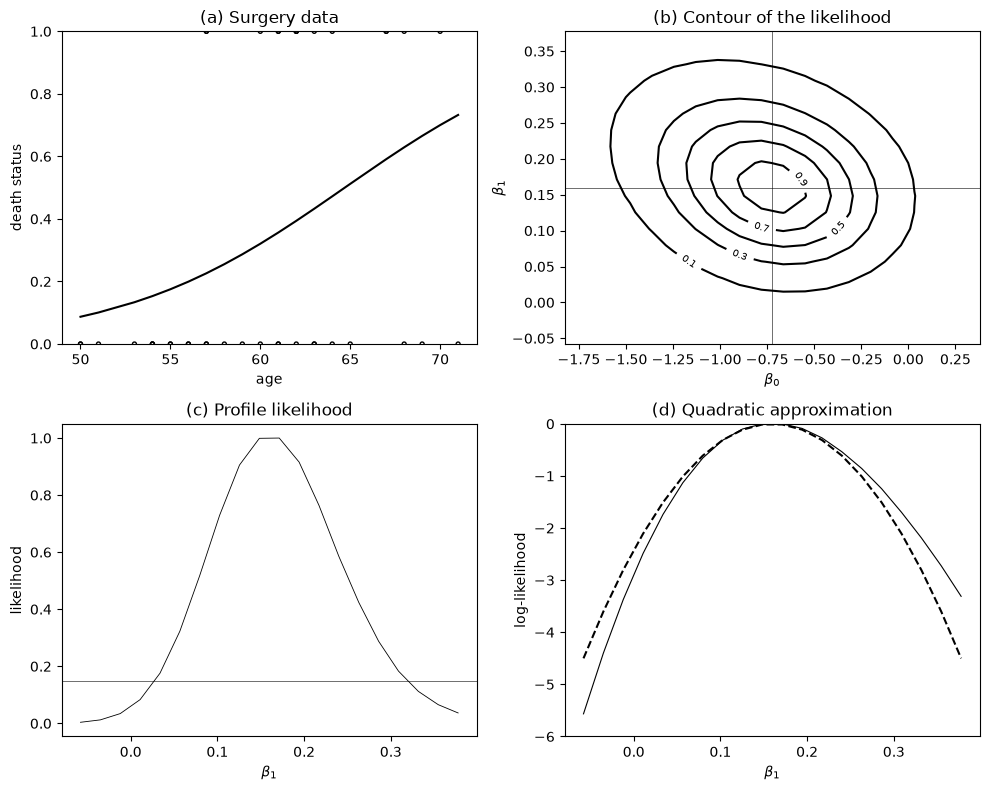

In [4]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(x, y, s=8, facecolors="none", edgecolors="k")
ax.set_ylim(0, 1)
ax.set_xlabel("age")
ax.set_ylabel("death status")
ax.set_title("(a) Surgery data")

# glm
x0 = x - x.mean()
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Binomial()).fit()
b = coef_table(xglm, ["(Intercept)", "x0"])
print(b)
ax.plot(x, xglm.fittedvalues, "k-")

# 2d likelihood
b0hat, b1hat = xglm.params
se0, se1 = xglm.bse


def fun1(bo, b1):
    return np.sum(y * (bo + b1 * x0) - np.log(1 + np.exp(bo + b1 * x0)))


bbo = np.linspace(b0hat - 3 * se0, b0hat + 3 * se0, 20)
bb1 = np.linspace(b1hat - 3 * se1, b1hat + 3 * se1, 20)
lik = np.array([[fun1(bo, b1) for b1 in bb1] for bo in bbo])
lik = np.exp(lik - lik.max())

ax = axes[1]
cs = ax.contour(bbo, bb1, lik.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=7)
ax.axhline(b1hat, color="k", lw=0.4)
ax.axvline(b0hat, color="k", lw=0.4)
ax.set_xlabel(r"$\beta_0$")
ax.set_ylabel(r"$\beta_1$")
ax.set_title("(b) Contour of the likelihood")

lik1 = lik.max(axis=0)

ax = axes[2]
ax.plot(bb1, lik1, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
print("95% CI for beta1=", np.round(li(bb1, lik1, .15), 3))
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("likelihood")
ax.set_title("(c) Profile likelihood")

# normal approx
se = se1
ll = np.log(lik1)
ll2 = -1 / 2 / se ** 2 * (bb1 - b1hat) ** 2
ax = axes[3]
ax.plot(bb1, ll, "k-", lw=0.8)
ax.plot(bb1, ll2, "k--")
ax.set_ylim(-6, 0)
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("log-likelihood")
ax.set_title("(d) Quadratic approximation")

fig.tight_layout()
plt.show()

## Example 6.4 (`EX6-4.R`)

In [5]:
x = scan("seed.dat").reshape(-1, 2)
y = x[:, 0]  # success
n = x[:, 1]  # number of planted seeds

seed = np.repeat([0, 1], [11, 10])
extract = np.repeat([0, 1, 0, 1], [5, 6, 5, 5])

# how the X matrix is set up
N = len(y)
X = np.zeros((N, 4))
X[:, 0] = 1
X[:, 1] = seed
X[:, 2] = extract
X[:, 3] = seed * extract

reg = sm.GLM(np.column_stack([y, n - y]), X, family=sm.families.Binomial()).fit()
print(coef_table(reg, ["(Intercept)", "seed", "extract", "seed:extract"]))

print(X)

              Estimate  Std. Error     value  Pr(>|value|)
(Intercept)  -0.558172    0.126021 -4.429187  9.458886e-06
seed          0.145927    0.223166  0.653894  5.131799e-01
extract       1.318182    0.177468  7.427729  1.104780e-13
seed:extract -0.778104    0.306433 -2.539228  1.110974e-02
[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 1. 0.]
 [1. 0. 1. 0.]
 [1. 0. 1. 0.]
 [1. 0. 1. 0.]
 [1. 0. 1. 0.]
 [1. 0. 1. 0.]
 [1. 1. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]


## Example 6.5 (`EX6-5.R`)

             Estimate  Std. Error     value  Pr(>|value|)
(Intercept)  0.425497    0.140901  3.019841      0.002529
x0           0.066260    0.026215  2.527613      0.011484


[0.01561609 0.11894689]


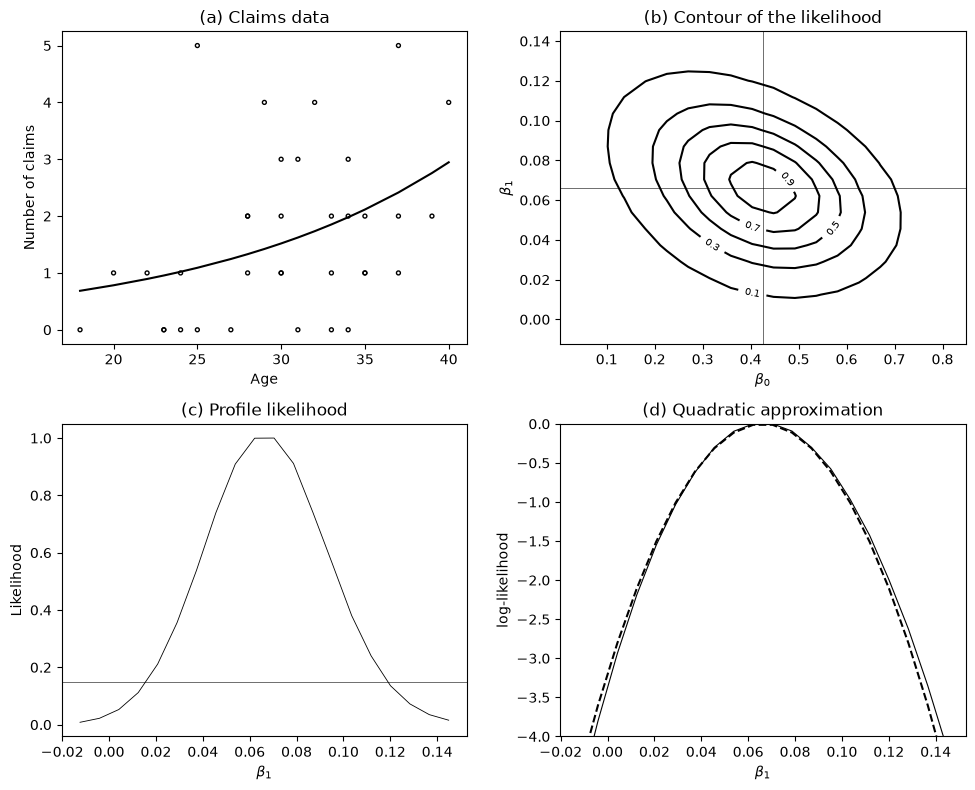

In [6]:
x, y = np.loadtxt(DATA / "claim.dat", unpack=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(x, y, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Age")
ax.set_ylabel("Number of claims")
ax.set_title("(a) Claims data")

# glm
x0 = x - x.mean()
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Poisson()).fit()
b = coef_table(xglm, ["(Intercept)", "x0"])
print(b)
b0hat, b1hat = xglm.params
se0, se1 = xglm.bse
etahat = b0hat + b1hat * x0
muhat = np.exp(etahat)
ax.plot(x, muhat, "k-")


# 2d likelihood
def fun1(bo, b1):
    return np.sum(y * (bo + b1 * x0) - np.exp(bo + b1 * x0))


bbo = np.linspace(b0hat - 3 * se0, b0hat + 3 * se0, 20)
bb1 = np.linspace(b1hat - 3 * se1, b1hat + 3 * se1, 20)
lik = np.array([[fun1(bo, b1) for b1 in bb1] for bo in bbo])
lik = np.exp(lik - lik.max())

ax = axes[1]
cs = ax.contour(bbo, bb1, lik.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=7)
ax.axhline(b1hat, color="k", lw=0.4)
ax.axvline(b0hat, color="k", lw=0.4)
ax.set_xlabel(r"$\beta_0$")
ax.set_ylabel(r"$\beta_1$")
ax.set_title("(b) Contour of the likelihood")

lik1 = lik.max(axis=0)
ax = axes[2]
ax.plot(bb1, lik1, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
print(li(bb1, lik1, .15))
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Likelihood")
ax.set_title("(c) Profile likelihood")

# normal approx
ll = np.log(lik1)
ll2 = -1 / 2 / se1 ** 2 * (bb1 - b1hat) ** 2
ax = axes[3]
ax.plot(bb1, ll, "k-", lw=0.8)
ax.plot(bb1, ll2, "k--")
ax.set_ylim(-4, 0)
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("log-likelihood")
ax.set_title("(d) Quadratic approximation")

fig.tight_layout()
plt.show()

## Example 6.6 (`EX6-6.R`)

In [7]:
acc0, acc1, year0, year1 = np.loadtxt(DATA / "accident.dat", unpack=True)

acc = np.concatenate([acc0, acc1])
year = np.concatenate([year0, year1])
site = np.tile(np.arange(1, 9), 2)
treat = np.repeat([0, 1], [8, 8])

xreg = sm.GLM(acc, sm.add_constant(treat), family=sm.families.Poisson(),
              offset=np.log(year)).fit()
print(coef_table(xreg, ["(Intercept)", "treat"]))

             Estimate  Std. Error     value  Pr(>|value|)
(Intercept)  0.516691    0.093659  5.516747  3.453310e-08
treat       -0.699012    0.274661 -2.545003  1.092767e-02


## Example 6.7 (`EX6-7.R`)

             Estimate  Std. Error      value  Pr(>|value|)
(Intercept)  0.035453    0.002280  15.548871      0.000001
x0           0.015506    0.002424   6.396255      0.000369


0.025168002284325745
beta0-hat= 0.03467339490028349 ,  se= 0.012326430250825617
beta1-hat= 0.015720822604606218 ,  se= 0.008462207648195424


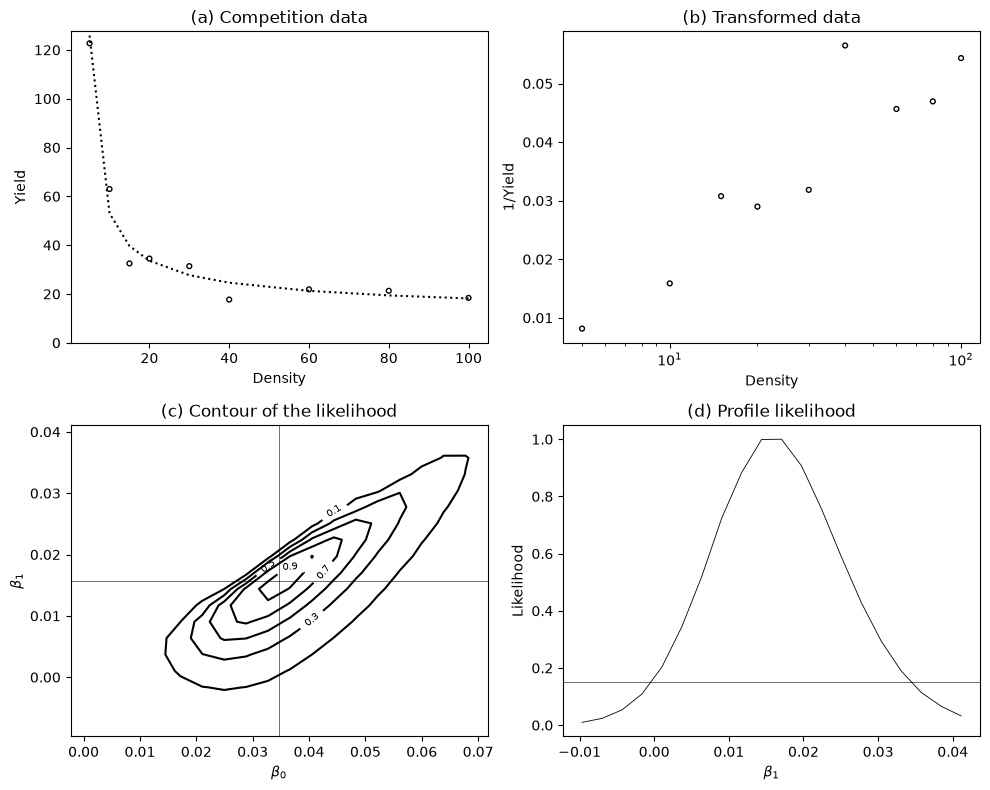

In [8]:
xdat = scan("compete.dat", skip=1).reshape(-1, 4)
y = xdat[:, 2]
den = xdat[:, 1]
n = len(y)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(den, y, s=12, facecolors="none", edgecolors="k")
ax.set_ylim(0, y.max() * 1.04)
ax.set_xlabel("Density")
ax.set_ylabel("Yield")
ax.set_title("(a) Competition data")

x0 = np.log(den) - np.log(den).mean()
a = sm.OLS(1 / y, sm.add_constant(x0)).fit()
print(coef_table(a, ["(Intercept)", "x0"]))

# The gamma fit produces the same parameter estimates as the exponential
# fit, but different standard errors.
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Gamma()).fit()
ax.plot(den, xglm.fittedvalues, "k:", lw=1.5)

ax = axes[1]
ax.scatter(den, 1 / y, s=12, facecolors="none", edgecolors="k")
ax.set_xscale("log")
ax.set_xlabel("Density")
ax.set_ylabel("1/Yield")
ax.set_title("(b) Transformed data")

# ................  glm
muhat = xglm.fittedvalues
phi = 1 / (n - 2) * np.sum((y - muhat) ** 2 / muhat ** 2)  # ....... phi=0.025
print(phi)

b0hat, b1hat = xglm.params
se0 = xglm.bse[0] / np.sqrt(0.025)
se1 = xglm.bse[1] / np.sqrt(0.025)
print("beta0-hat=", b0hat, ",  se=", se0)
print("beta1-hat=", b1hat, ",  se=", se1)


def fun1(bo, b1):
    a = np.where((bo + b1 * x0) < 0.00001, 0.00001, bo + b1 * x0)
    return np.sum(-y * a + np.log(a))


bbo = np.linspace(b0hat - 3 * se0, b0hat + 3 * se0, 20)
bb1 = np.linspace(b1hat - 3 * se1, b1hat + 3 * se1, 20)
lik = np.array([[fun1(bo, b1) for b1 in bb1] for bo in bbo])
lik = np.exp(lik - lik.max())

ax = axes[2]
cs = ax.contour(bbo, bb1, lik.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=7)
ax.axhline(b1hat, color="k", lw=0.4)
ax.axvline(b0hat, color="k", lw=0.4)
ax.set_xlabel(r"$\beta_0$")
ax.set_ylabel(r"$\beta_1$")
ax.set_title("(c) Contour of the likelihood")

lik1 = lik.max(axis=0)

ax = axes[3]
ax.plot(bb1, lik1, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Likelihood")
ax.set_title("(d) Profile likelihood")

fig.tight_layout()
plt.show()

## Example 6.7 continued (`EX6-7C.R`)

For the table on page 166.

In [9]:
xdat = scan("compete.dat", skip=1).reshape(-1, 4)
y = xdat[:, 2]
den = xdat[:, 1]
n = len(y)
x0 = np.log(den) - np.log(den).mean()  # as in Example 6.7

# The gamma fit produces the same parameter estimates as the exponential
# fit, but different standard errors.
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Gamma()).fit()
print(coef_table(xglm, ["(Intercept)", "x0"]))

             Estimate  Std. Error      value  Pr(>|value|)
(Intercept)  0.034673    0.001949  17.790536  8.367529e-71
x0           0.015721    0.001338  11.749559  7.098793e-32


## Example 6.11 (`EX6-11.R`)

In [10]:
x, y = np.loadtxt(DATA / "surgery.dat", unpack=True)

# glm
x0 = x - x.mean()
xglm = sm.GLM(y, sm.add_constant(x0), family=sm.families.Binomial()).fit()
print(xglm.summary(xname=["(Intercept)", "x0"]))
print("Null deviance=", xglm.null_deviance, ", df=", xglm.nobs - 1)
print("Deviance of Const+Age=", xglm.deviance, ", df=", xglm.df_resid)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   40
Model:                            GLM   Df Residuals:                       38
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -23.000
Date:                Sat, 10 Oct 2026   Deviance:                       45.999
Time:                        18:03:43   Pearson chi2:                     37.4
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1349
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
(Intercept)    -0.7226      0.368     -1.965      

## `EX6-12.R`

This script is headed "Example 6.6" and repeats Example 6.6 with the full
model summary.

In [11]:
acc0, acc1, year0, year1 = np.loadtxt(DATA / "accident.dat", unpack=True)

acc = np.concatenate([acc0, acc1])
year = np.concatenate([year0, year1])
site = np.tile(np.arange(1, 9), 2)
treat = np.repeat([0, 1], [8, 8])

xreg = sm.GLM(acc, sm.add_constant(treat), family=sm.families.Poisson(),
              offset=np.log(year)).fit()
print(xreg.summary(xname=["(Intercept)", "treat"]))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   16
Model:                            GLM   Df Residuals:                       14
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -50.055
Date:                Sat, 10 Oct 2026   Deviance:                       50.863
Time:                        18:03:43   Pearson chi2:                     53.4
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3830
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
(Intercept)     0.5167      0.094      5.517      

## Example 6.15 (`EX6-15.R`)

                 Generalized Linear Model Regression Results                  
Dep. Variable:           ['y1', 'y2']   No. Observations:                    4
Model:                            GLM   Df Residuals:                        0
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -4.5489
Date:                Sat, 10 Oct 2026   Deviance:                   2.5830e-09
Time:                        18:03:43   Pearson chi2:                 1.29e-09
No. Iterations:                    20   Pseudo R-squ. (CS):             0.9995
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -21.5661   1.69e+04     -0.001      0.9

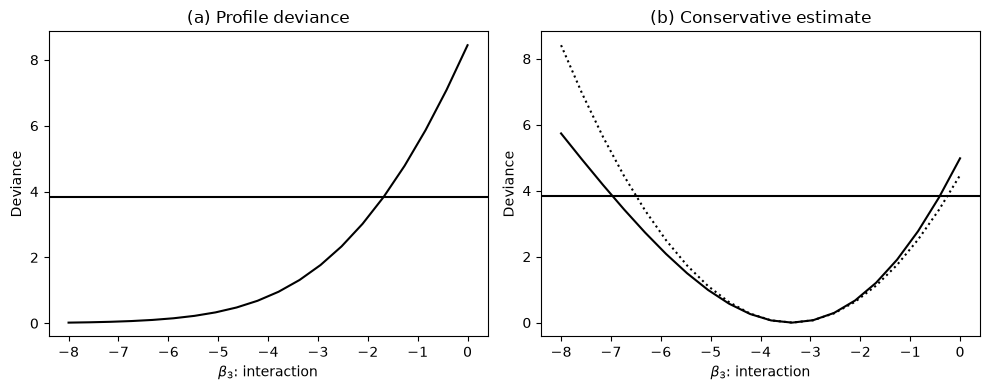

In [12]:
x = scan("trade.dat", skip=1).reshape(-1, 5)
manag = x[:, 0:2].copy()
city = x[:, 2]
domest = x[:, 3]

X_int = np.column_stack([np.ones(4), domest, city, domest * city])
X_add = np.column_stack([np.ones(4), domest, city])

# results may be different from the text due to numerical problems
# (statsmodels warns about these; the warnings are silenced here)
warnings.simplefilter("ignore", PerfectSeparationWarning)
warnings.simplefilter("ignore", RuntimeWarning)
xglm0 = sm.GLM(manag, X_int, family=sm.families.Binomial()).fit()
print(xglm0.summary())

xglm1 = sm.GLM(manag, X_add, family=sm.families.Binomial()).fit()
print("Deviance of additive model=", xglm1.deviance)


def profile_deviance(manag, theta):
    dev = []
    for a in theta:
        inter = a * domest * city
        fit = sm.GLM(manag, X_add, family=sm.families.Binomial(), offset=inter).fit()
        dev.append(fit.deviance)
    return np.array(dev)


theta = np.linspace(-8, 0, 20)
dev = profile_deviance(manag, theta)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(theta, dev, "k-")
ax.axhline(3.84, color="k")
ax.set_xlabel(r"$\beta_3$: interaction")
ax.set_ylabel("Deviance")
ax.set_title("(a) Profile deviance")

# ..........   conservative analysis: changing 0 to 1
manag[0, 0] = 1

dev = profile_deviance(manag, theta)

ax = axes[1]
ax.plot(theta, dev, "k-")
ax.axhline(3.84, color="k")

xglm0 = sm.GLM(manag, X_int, family=sm.families.Binomial()).fit()

# normal approximation:
nlike = stats.norm.pdf(theta, xglm0.params[3], xglm0.bse[3])
wilk = 2 * (np.log(nlike).max() - np.log(nlike))
ax.plot(theta, wilk, "k:", lw=1.5)
ax.set_xlabel(r"$\beta_3$: interaction")
ax.set_ylabel("Deviance")
ax.set_title("(b) Conservative estimate")
fig.tight_layout()
plt.show()

## Example 6.16 (`EX6-16.R`)

In [13]:
age, claim = np.loadtxt(DATA / "claim.dat", unpack=True)
age0 = age - age.mean()
n = len(age)

# IWLS
X = np.column_stack([np.ones(n), age0])
bt = np.array([np.log(claim.mean()), 0])  # starting value
print("iteration= 0 , betahat =", bt)
for i in range(1, 5):
    Xbt = X @ bt
    mu = np.exp(Xbt)
    Y = Xbt + (claim - mu) / mu
    S = 1 / mu  # this is a vector of variances, no need to turn it into a matrix
    XS = X * (S ** -1)[:, None]
    XSX = XS.T @ X
    XSY = XS.T @ Y
    bt = np.linalg.solve(XSX, XSY)
    print("iteration= ", i, ", betahat=", bt)

print("Covariance matrix of betahat")
print(np.linalg.inv(XSX))
se2 = np.diag(np.linalg.inv(XSX))
print("standard errors of betahat", np.sqrt(se2))

# for comparison
xglm = sm.GLM(claim, sm.add_constant(age0), family=sm.families.Poisson()).fit()
print("From GLM run:")
print(coef_table(xglm, ["(Intercept)", "age0"]))

iteration= 0 , betahat = [0.48770321 0.        ]
iteration=  1 , betahat= [0.48770321 0.0620757 ]
iteration=  2 , betahat= [0.42761843 0.06601483]
iteration=  3 , betahat= [0.42550056 0.0662597 ]
iteration=  4 , betahat= [0.42549749 0.06626019]
Covariance matrix of betahat
[[ 0.01985291 -0.00125968]
 [-0.00125968  0.0006872 ]]
standard errors of betahat [0.14090036 0.02621449]
From GLM run:
             Estimate  Std. Error     value  Pr(>|value|)
(Intercept)  0.425497    0.140901  3.019841      0.002529
age0         0.066260    0.026215  2.527613      0.011484


## Example 6.18a (`EX6-18A.R`)

To produce Figure 6.8 and the first table on page 180.

| Variable | Description |
|---|---|
| Y  | SO2 content of air in micrograms per cubic metre |
| X1 | Average annual temperature in °F |
| X2 | Number of manufacturing enterprises employing 20 or more workers |
| X3 | Population size (1970 census); in thousands |
| X4 | Average annual wind speed in miles per hour |
| X5 | Average annual precipitation in inches |
| X6 | Average annual of days with precipitation per year |

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.423
Model:                            OLS   Adj. R-squared:                  0.392
Method:                 Least Squares   F-statistic:                     13.92
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           2.92e-05
Time:                        18:03:43   Log-Likelihood:                -175.79
No. Observations:                  41   AIC:                             357.6
Df Residuals:                      38   BIC:                             362.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
(Intercept)   231.4431     68.371      3.385      

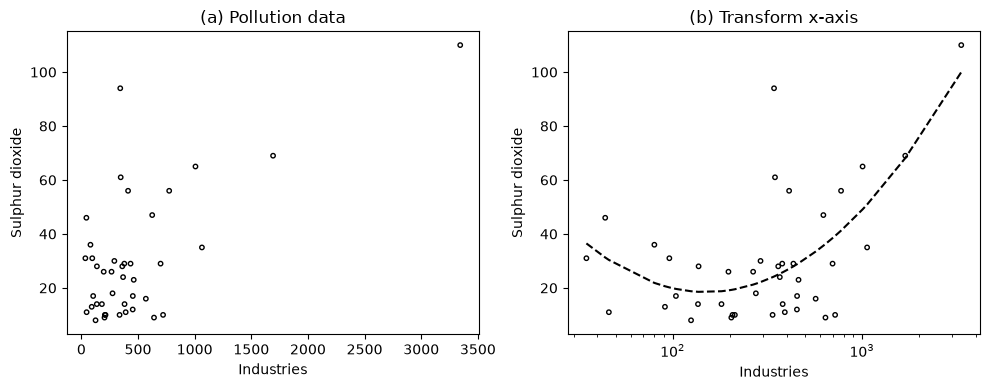

In [14]:
x = scan("air.dat", skip=9).reshape(-1, 7)
y = x[:, 0]
x = x[:, 2]
order = np.argsort(x, kind="stable")
x = x[order]
y = y[order]
n = len(x)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
ax.set_xlabel("Industries")
ax.set_ylabel("Sulphur dioxide")
ax.set_title("(a) Pollution data")

ax = axes[1]
ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
ax.set_xscale("log")
ax.set_xlabel("Industries")
ax.set_ylabel("Sulphur dioxide")
ax.set_title("(b) Transform x-axis")

lx = np.log(x)
lx2 = lx ** 2
xreg = sm.OLS(y, sm.add_constant(np.column_stack([lx, lx2]))).fit()
ax.plot(x, xreg.fittedvalues, "k--")
print(xreg.summary(xname=["(Intercept)", "lx", "lx2"]))

a1 = qqnorm(xreg.resid)
fig.tight_layout()
plt.show()

## Example 6.18b (`EX6-18B.R`)

To produce Figure 6.9 and the second table on page 180.

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     7.129
Date:                Sat, 10 Oct 2026   Prob (F-statistic):            0.00235
Time:                        18:03:43   Log-Likelihood:                -36.650
No. Observations:                  41   AIC:                             79.30
Df Residuals:                      38   BIC:                             84.44
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
(Intercept)     8.1415      2.296      3.546      

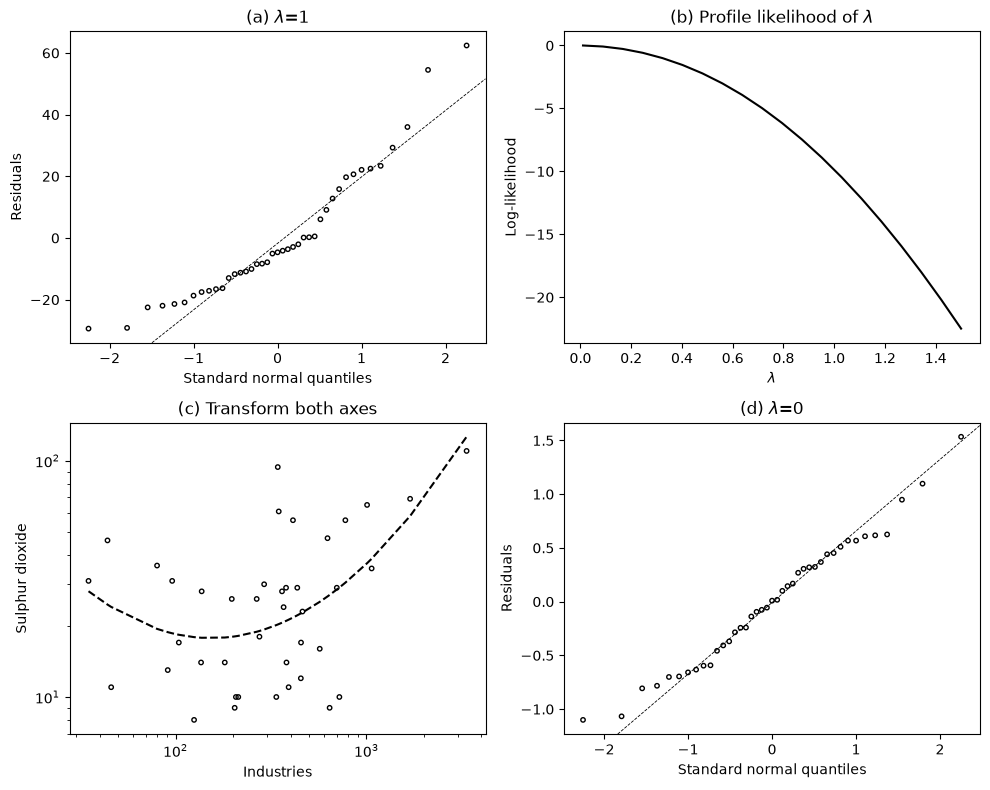

In [15]:
x = scan("air.dat", skip=9).reshape(-1, 7)
y = x[:, 0]
x = x[:, 2]
order = np.argsort(x, kind="stable")
x = x[order]
y = y[order]
n = len(x)

lx = np.log(x)
# The R code is lm(y ~ lx + lx^2).  In an R formula lx^2 is the same as lx,
# so this is a straight-line fit in lx.
xreg = sm.OLS(y, sm.add_constant(lx)).fit()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

# normal plots:
ax = axes[0]
q, s = qqnorm(xreg.resid)
ax.scatter(q, s, s=10, facecolors="none", edgecolors="k")
qqline(ax, xreg.resid, color="k", ls="--", lw=0.6)
ax.set_xlabel("Standard normal quantiles")
ax.set_ylabel("Residuals")
ax.set_title(r"(a) $\lambda$=1")

# finding lambda-hat
nl = 20
lam = np.linspace(.01, 1.5, nl)
ll = []
for li_ in lam:
    yl = (y ** li_ - 1) / li_
    res = yl - np.polyval(np.polyfit(lx, yl, 2), lx)  # residuals of yl ~ poly(lx, 2)
    sl2 = np.sum(res ** 2) / (n - 3)
    ll.append(-n / 2 * np.log(sl2) + (li_ - 1) * np.sum(np.log(y)))
ll = np.array(ll)
ll = ll - ll.max()
ax = axes[1]
ax.plot(lam, ll, "k-")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("Log-likelihood")
ax.set_title(r"(b) Profile likelihood of $\lambda$")
lmax = lam[ll == ll.max()].max()

ax = axes[2]
ax.scatter(x, y, s=10, facecolors="none", edgecolors="k")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Industries")
ax.set_ylabel("Sulphur dioxide")
ax.set_title("(c) Transform both axes")

lx2 = lx ** 2
xreg = sm.OLS(np.log(y), sm.add_constant(np.column_stack([lx, lx2]))).fit()
print(xreg.summary(xname=["(Intercept)", "lx", "lx2"]))
ax.plot(x, np.exp(xreg.fittedvalues), "k--")

ax = axes[3]
q, s = qqnorm(xreg.resid)
ax.scatter(q, s, s=10, facecolors="none", edgecolors="k")
qqline(ax, xreg.resid, color="k", ls="--", lw=0.6)
ax.set_xlabel("Standard normal quantiles")
ax.set_ylabel("Residuals")
ax.set_title(r"(d) $\lambda$=0")

fig.tight_layout()
plt.show()

## Example 6.19 (`EX6-19A.R`)

Stack loss versus air flow.

              Estimate  Std. Error      value  Pr(>|value|)
(Intercept) -44.132025    6.105858  -7.227818  7.314184e-07
x             1.020309    0.099953  10.207905  3.774296e-09
Normal AIC=  160.26072836430157
Cauchy-based estimates for beta0, beta1, sigma [-41.37169889   0.97435434   1.27989512]
Cauchy AIC=  115.49338632838273
[-41.37169889   0.97435434   1.27989512]
Standard errors of beta0-hat and beta1-hat 0.09995286602452978 0.04505217820319534


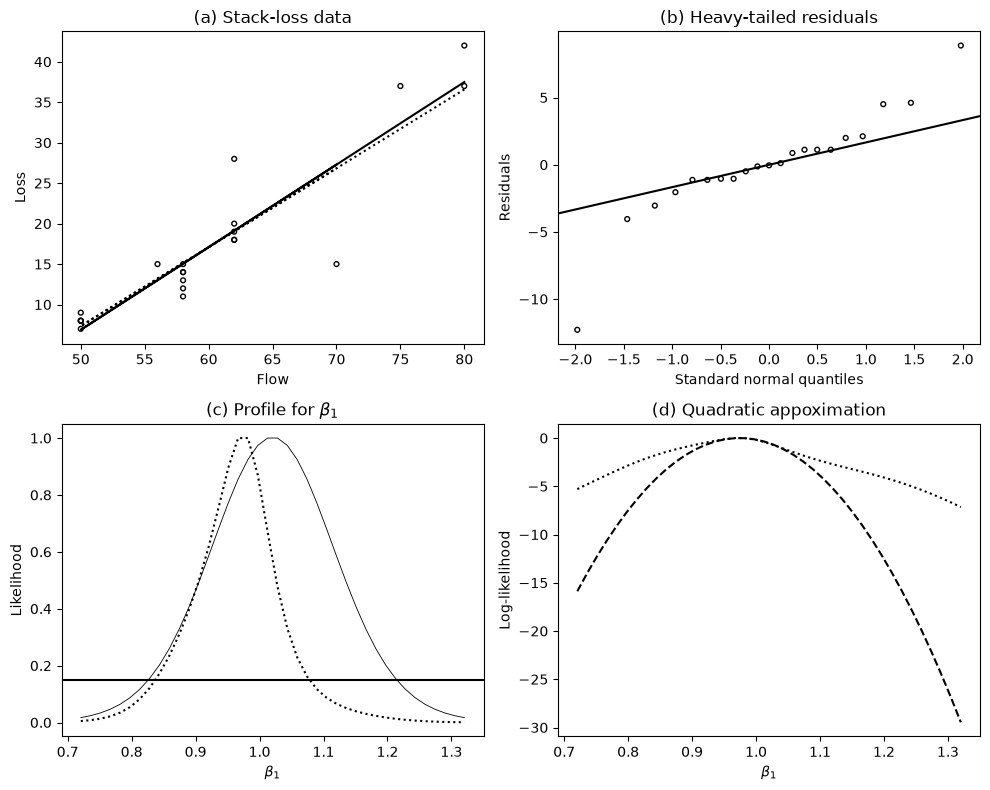

In [16]:
def cauchy_nll(y, mu, sigma):
    """Minus log-likelihood of the Cauchy model."""
    if sigma <= 0:
        return np.inf
    return -np.sum(stats.cauchy.logpdf(y, mu, sigma))


x = scan("stack.dat", skip=11).reshape(-1, 4)
flow = x[:, 0]
cooling = x[:, 1]
concen = x[:, 2]
loss = x[:, 3]

y = loss
x = flow
n = len(x)
x0 = x - x.mean()

a = sm.OLS(y, sm.add_constant(x)).fit()
print(coef_table(a, ["(Intercept)", "x"]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.scatter(x, y, s=12, facecolors="none", edgecolors="k")
ax.plot(x, a.fittedvalues, "k-")
ax.set_xlabel("Flow")
ax.set_ylabel("Loss")
ax.set_title("(a) Stack-loss data")

# log-likelihood:
bo, b1 = a.params
sigma = np.sum(a.resid ** 2) / n  # (EX6-19B.R takes the square root here)
mu = bo + b1 * x
aic = -2 * np.sum(np.log(stats.norm.pdf(y, mu, sigma))) + 6  # normal model
print("Normal AIC= ", aic)


def fun1(p):  # cauchy model
    bo, b1, sigma = p
    return cauchy_nll(y, bo + b1 * x, sigma)


ams = optimize.minimize(fun1, [-44, 1, 1], method="Nelder-Mead",
                        options={"maxiter": 5000, "xatol": 1e-8, "fatol": 1e-10})
print("Cauchy-based estimates for beta0, beta1, sigma", ams.x)
print("Cauchy AIC= ", 2 * ams.fun + 6)

mu = ams.x[0] + ams.x[1] * x
ax.plot(x, mu, "k:", lw=1.5)
print(ams.x)

ax = axes[1]
q, s = qqnorm(a.resid)
ax.scatter(q, s, s=12, facecolors="none", edgecolors="k")
qqline(ax, a.resid, color="k")
ax.set_xlabel("Standard normal quantiles")
ax.set_ylabel("Residuals")
ax.set_title("(b) Heavy-tailed residuals")

b1hat, se = a.params[1], a.bse[1]
bb1 = np.linspace(b1hat - 3 * se, b1hat + 3 * se, 40)


def fun2(b1):
    bo = y.mean() - b1 * x.mean()
    return -n / 2 * np.log(np.sum((y - bo - b1 * x) ** 2))


ll = np.array([fun2(b1) for b1 in bb1])
ll = ll - ll.max()
like = np.exp(ll - ll.max())
ax = axes[2]
ax.plot(bb1, like, "k-", lw=0.6)
ax.axhline(.15, color="k")
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(c) Profile for $\beta_1$")

# Cauchy profile likelihood of b1, maximising over (b0, sigma)
llc = []
for b1 in bb1:
    def fun1(p):  # cauchy model
        bo, sigma = p
        return cauchy_nll(y, bo + b1 * x0, sigma)
    llc.append(optimize.minimize(fun1, [17, 1], method="Nelder-Mead").fun)
llc = np.array(llc)
llc = llc.min() - llc
likec = np.exp(llc)
ax.plot(bb1, likec, "k:", lw=1.5)

info = -np.diff(llc, n=2) / (bb1[1] - bb1[0]) ** 2
aa = bb1[1:-1]
info = approx(aa, info, 0.97)
sec = np.sqrt(1 / info)
print("Standard errors of beta0-hat and beta1-hat", se, sec)

ax = axes[3]
ax.plot(bb1, llc, "k:", lw=1.5)
ll2 = -1 / 2 / sec ** 2 * (bb1 - ams.x[1]) ** 2
ax.plot(bb1, ll2, "k--")
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Log-likelihood")
ax.set_title("(d) Quadratic appoximation")

fig.tight_layout()
plt.show()

## Example 6.19 (`EX6-19B.R`)

Stack loss versus cooling temperature.

              Estimate  Std. Error     value  Pr(>|value|)
(Intercept) -41.910867    7.605621 -5.510512  2.575258e-05
x             2.817445    0.356744  7.897672  2.028017e-07
Normal AIC=  131.44734458814642
Cauchy AIC=  141.43866556423052
Cauchy-based estimates for beta0, beta1, sigma [-20.68920473   1.71585097   2.71256145]
[-20.68920473   1.71585097   2.71256145]
Standard errors of beta0-hat and beta1-hat 0.35674375358181437 0.5042189140795963


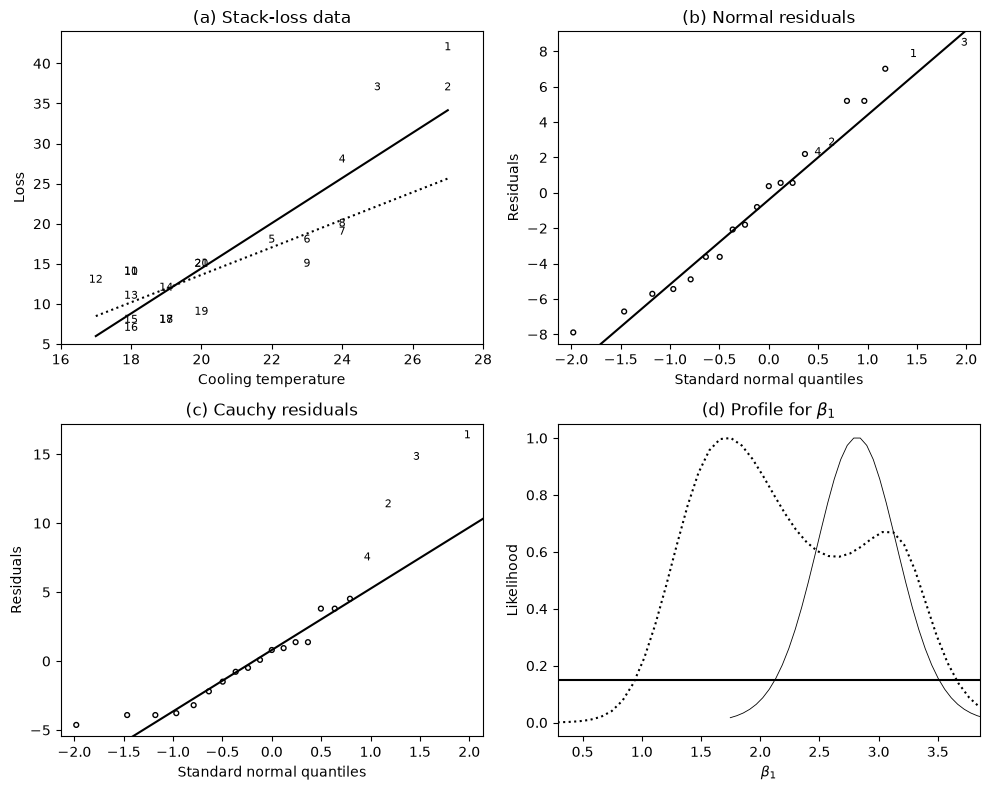

In [17]:
x = scan("stack.dat", skip=11).reshape(-1, 4)
flow = x[:, 0]
cooling = x[:, 1]
concen = x[:, 2]
loss = x[:, 3]

y = loss
x = cooling
n = len(x)
x0 = x - x.mean()

# normal model:
a = sm.OLS(y, sm.add_constant(x)).fit()
print(coef_table(a, ["(Intercept)", "x"]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
for i in range(n):
    ax.text(x[i], y[i], str(i + 1), fontsize=8, ha="center", va="center")
ax.set_xlim(x.min() - 1, x.max() + 1)
ax.set_ylim(y.min() - 2, y.max() + 2)
order = np.argsort(x, kind="stable")
ax.plot(x[order], a.fittedvalues[order], "k-")
ax.set_xlabel("Cooling temperature")
ax.set_ylabel("Loss")
ax.set_title("(a) Stack-loss data")

# AIC:
bo, b1 = a.params
sigma = np.sqrt(np.sum(a.resid ** 2) / n)
mu = bo + b1 * x
aic = -2 * np.sum(np.log(stats.norm.pdf(y, mu, sigma))) + 6  # normal model
print("Normal AIC= ", aic)


def fun1(p):  # cauchy model
    bo, b1, sigma = p
    return cauchy_nll(y, bo + b1 * x, sigma)


ams = optimize.minimize(fun1, [-20, 1, 2], method="Nelder-Mead",
                        options={"maxiter": 5000, "xatol": 1e-8, "fatol": 1e-10})
print("Cauchy AIC= ", 2 * ams.fun + 6)
print("Cauchy-based estimates for beta0, beta1, sigma", ams.x)

mu = ams.x[0] + ams.x[1] * x
ax.plot(x[order], mu[order], "k:", lw=1.5)
print(ams.x)
amsres = y - mu


def label_qqplot(ax, res, title):
    """Normal plot with the first four observations labelled 1-4."""
    q, s = qqnorm(res)
    ax.scatter(q[4:], s[4:], s=12, facecolors="none", edgecolors="k")
    for i in range(4):
        ax.text(q[i], s[i], str(i + 1), fontsize=8, ha="center", va="center")
    pad_q = 0.04 * np.ptp(q)
    pad_s = 0.04 * np.ptp(s)
    ax.set_xlim(q.min() - pad_q, q.max() + pad_q)  # axes cover all points, as in R
    ax.set_ylim(s.min() - pad_s, s.max() + pad_s)
    qqline(ax, res, color="k")
    ax.set_xlabel("Standard normal quantiles")
    ax.set_ylabel("Residuals")
    ax.set_title(title)


label_qqplot(axes[1], a.resid, "(b) Normal residuals")
label_qqplot(axes[2], amsres, "(c) Cauchy residuals")

b1hat, se = a.params[1], a.bse[1]
bb1 = np.linspace(b1hat - 3 * se, b1hat + 3 * se, 40)


def fun2(b1):
    bo = y.mean() - b1 * x.mean()
    return -n / 2 * np.log(np.sum((y - bo - b1 * x) ** 2))


ll = np.array([fun2(b1) for b1 in bb1])
ll = ll - ll.max()
like = np.exp(ll - ll.max())

# Cauchy profile likelihood of b1, maximising over (b0, sigma)
bbc = np.linspace(ams.x[1] - 4 * se, ams.x[1] + 6 * se, 40)
llc = []
for b1 in bbc:
    def fun1(p):  # cauchy model
        bo, sigma = p
        return cauchy_nll(y, bo + b1 * x0, sigma)
    llc.append(optimize.minimize(fun1, [17, 1], method="Nelder-Mead").fun)
llc = np.array(llc)
llc = llc.min() - llc
likec = np.exp(llc)

ax = axes[3]
ax.plot(bb1, like, "k-", lw=0.6)
ax.set_xlim(bbc.min(), bbc.max())
ax.axhline(.15, color="k")
ax.plot(bbc, likec, "k:", lw=1.5)  # cauchy model
ax.set_xlabel(r"$\beta_1$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(d) Profile for $\beta_1$")

info = -np.diff(llc, n=2) / (bbc[1] - bbc[0]) ** 2
aa = bbc[1:-1]
info = approx(aa, info, ams.x[1])
sec = np.sqrt(1 / info)
print("Standard errors of beta0-hat and beta1-hat", se, sec)

fig.tight_layout()
plt.show()